In [1]:
from ipywidgets import interact, FloatSlider
from IPython.display import display

import matplotlib.pyplot as plt
import numpy as np

import crimper

Insert here the crimper dimansions

In [2]:
N = 15

Rp = 37.7

drive_ring_travel = 20


#crimp head geometry

bd = 11.3
sd = -0.8

bp =37.6
sp = -2.6

drive_pin_diameter = 3

W = 0.3*Rp
bl = W / np.tan((2*np.pi/N))
lb = max(bp + 0.09*Rp, bl + 0.08*Rp)

print(W)



11.31


In [3]:
print(f"blade angle= {np.rad2deg(2*np.pi/N)}")

a = bp-bd

print(a)
c = sd - sp
print(c)

L = np.hypot(a,c)
print(L)

max_hub_angle = np.asin(L/Rp)

print(np.rad2deg(max_hub_angle))

blade angle= 24.0
26.3
1.8
26.36152499382386
44.36643712647596


In [4]:
def blade_pose(drive_ring_angle,blade_number=0):

    alpha = (2*np.pi/(N))*blade_number

    O=np.array([0,0])
    P=np.array([Rp*np.cos(alpha),Rp*np.sin(alpha)])

    delta = np.deg2rad(drive_ring_angle)
    # calculate the distace to the drive ring for a given drive ring angle
    r = Rp*np.cos(delta) - np.sqrt(L**2 - (Rp*np.sin(delta))**2)

    # Q is the location of the drive pin

    Q = r*np.array([np.cos(delta+alpha), np.sin(delta+alpha)])
    
    w = Q - P

    # orientation of the crimper head

    beta = np.atan2(w[1],w[0])

    
    phi = beta - np.atan2(c,a)

    # cordinate system u and n in global cordinates
    
    u=np.array([np.cos(phi), np.sin(phi)])
    n=np.array([-np.sin(phi), np.cos(phi)])

    # location of crimp head tip 
    
    T= Q + bd*u - sd*n
   # assert np.allclose(T[i], P[i] + bp*u[i] - sp*n[i]) 

    # body of the crimper head
    
    # blade coordinates (b behind the tip, s sideways) of the four corners
    local = np.array([[0,  0],     # tip T
                      [bl, -W],    # end of the angled face
                      [lb, -W],    # rear, far side
                      [lb,  0],
                      [0,0]])
    # rear, on the flat face line
    
    Rb = np.column_stack((-u, n)) # column 1 = -u (backwards), column 2 = n (sideways)
    body= T + local @ Rb.T        # one row per corner, in world coordinates
    D_tip =  {2*np.hypot(T[0],T[1])}


    return O,Q,P,T,body,D_tip

In [5]:
def plot_mechanism(drive_angle):

    fig, ax = plt.subplots(figsize=(7, 6))

    D_tip = 0 

    for i in range(N):

        O,Q,P,T,body,D = blade_pose(drive_angle,i)
         
    
        ax.plot(
            [O[0], Q[0]],
            [O[1], Q[1]],
            'g--',
            linewidth=1,
            label='r'
        )
    
        ax.plot(
            [P[0], Q[0]],
            [P[1], Q[1]],
            'g--',
            linewidth=1,
            label='L'
        )
    
    
        x = []
        y = []
        for point in body:
            x.append(point[0])
            y.append(point[1])
    
        ax.plot(
            x,
            y,
            'k-',
            linewidth=1,
            label='T'
        )

    

    
    
    ax.set_aspect('equal')
    ax.grid(True)

    # Center view around origin
    ax.set_xlim(-50, 50)
    ax.set_ylim(-50, 50)
    
    # Put axes through (0,0)


    ax.set_title(f"Actuation angle = {drive_angle:.1f}°")

    plt.show()


AttributeError: 'Crimper' object has no attribute 'arctan2'

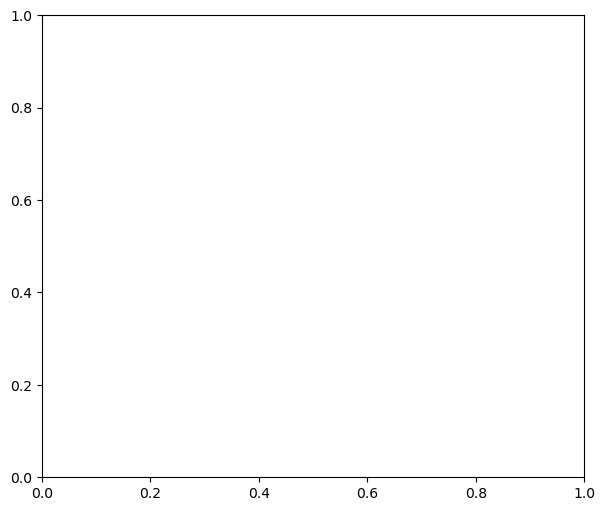

In [8]:
plot_mechanism(15)

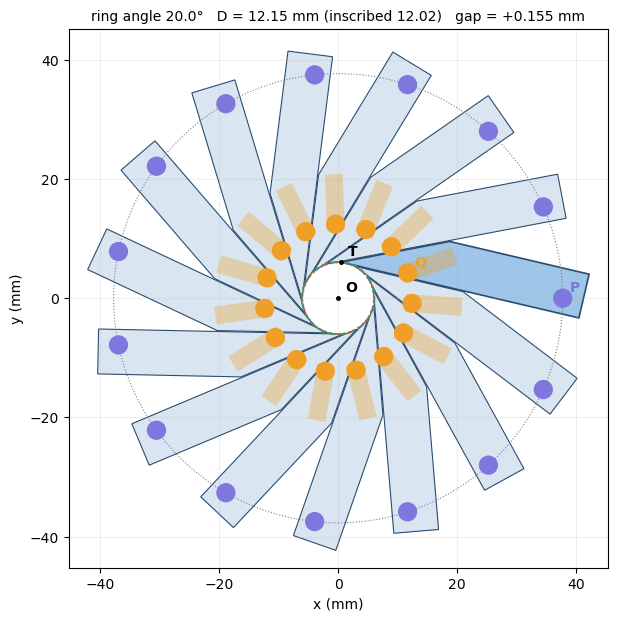

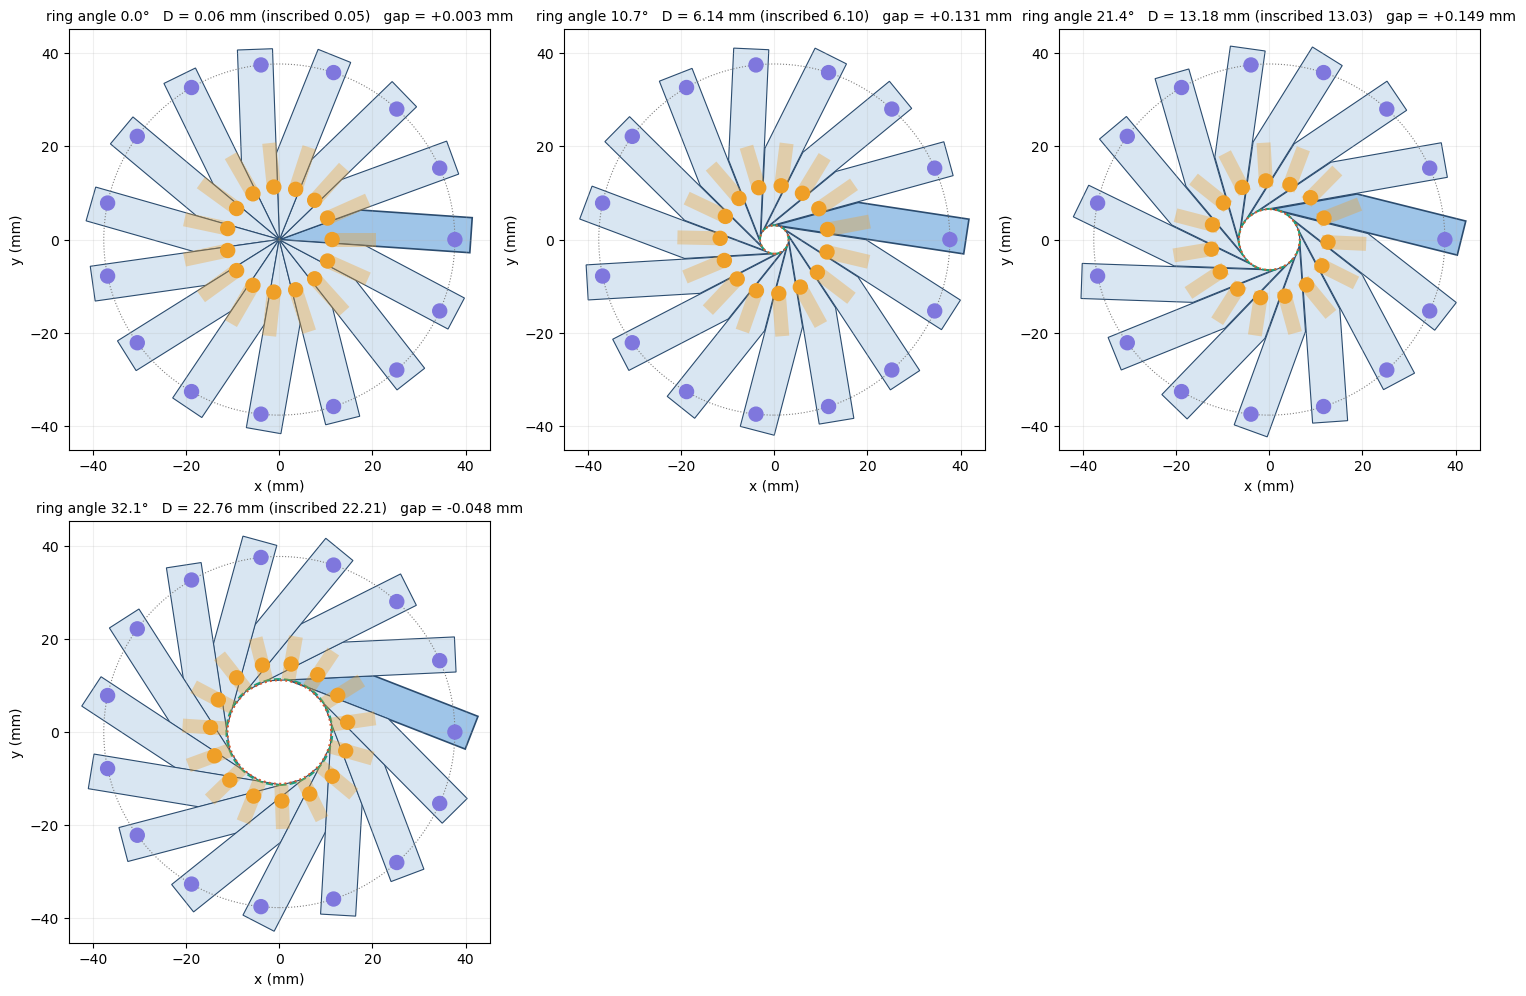

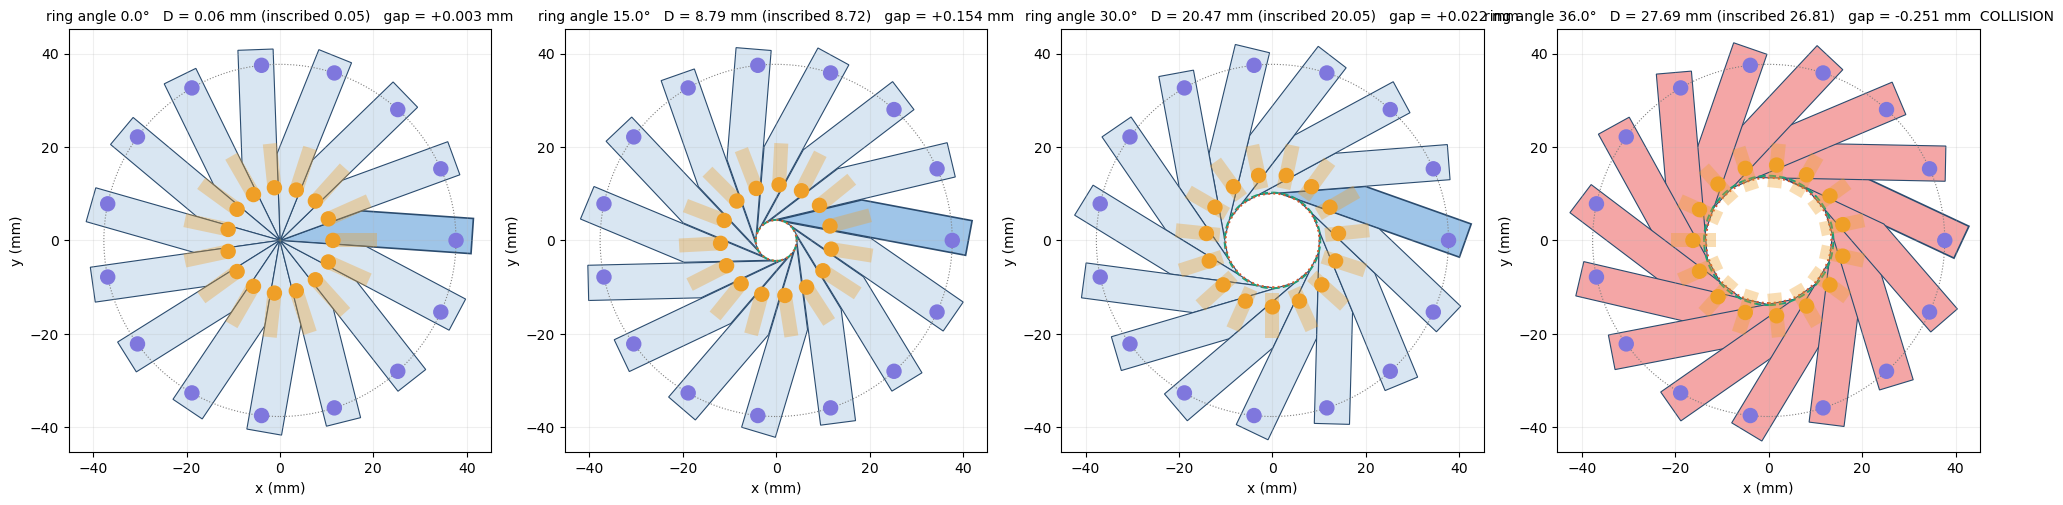

interactive(children=(FloatSlider(value=20.0, description='ring angle', max=42.36643712647596, step=0.5), Outp…

<function crimper.Crimper.interactive.<locals>.draw(delta)>

In [10]:
c = crimper.Crimper(N=15, Rp=37.7, bd=11.3, sd=-0.8, bp=37.6, sp=-2.6, width_factor=0.2)

c.plot(20, labels=True)        # one snapshot with O, P, Q, T labelled
c.plot_sequence()              # closed, 1/3, 2/3 and the collision-free maximum
c.plot_sequence([0, 15, 30, 36], ncols=4)
c.interactive()